<a href="https://colab.research.google.com/github/RUSHILPATEL33/SMS-Spam-Classifier/blob/main/SMS_Span_Classifier(NLP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [25]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [26]:
df.shape

(5572, 2)

In [27]:
df.isnull().sum()

,0
label,0
message,0


In [28]:
df.duplicated().sum()

np.int64(403)

In [29]:
df['label'].value_counts(normalize=True)

,proportion
label,
ham,0.865937
spam,0.134063


In [30]:
df[df.duplicated()].head(5)

,label,message
103,ham,As per your request 'Melle Melle (Oru Minnamin...
154,ham,As per your request 'Melle Melle (Oru Minnamin...
207,ham,"As I entered my cabin my PA said, '' Happy B'd..."
223,ham,"Sorry, I'll call later"
326,ham,No calls..messages..missed calls


In [31]:
df[df.duplicated()]['label'].value_counts()

,count
label,
ham,309
spam,94


In [32]:
df = df.drop_duplicates()
df.shape
df['label'].value_counts(normalize=True)

,proportion
label,
ham,0.87367
spam,0.12633


In [33]:
df.shape

(5169, 2)

In [34]:
df['length'] = df['message'].apply(len)

In [35]:
df.groupby('label')['length'].mean()

,length
label,
ham,70.905890
spam,137.704441


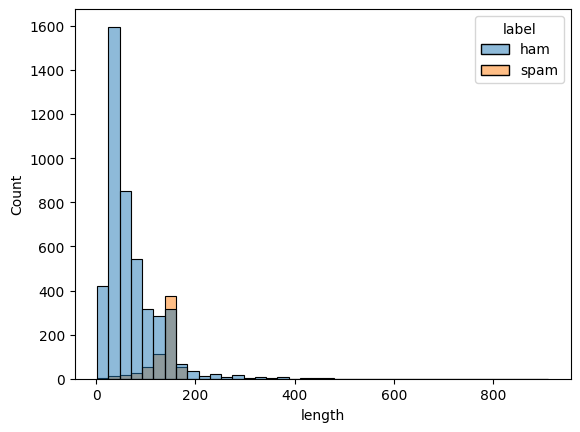

In [36]:
sns.histplot(data =df, x = 'length',hue='label',bins=40)
plt.show()

In [37]:
#Clean the text
import re

def clean_txt(text):
  text = text.lower()
  text = re.sub(r'[^a-z\s]', '', text)
  return text

df['clean'] = df['message'].apply(clean_txt)
df[['message','clean']].head()

,message,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [38]:
#split and then turn into numbers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

y=df['label'].map({'ham':0,'spam':1})
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean'], y, test_size=0.2, random_state=42, stratify=y
)

#vectorization
tfidf = TfidfVectorizer(stop_words='english')
X_train = tfidf.fit_transform(X_train_text)
X_test  = tfidf.transform(X_test_text)

X_train.shape, X_test.shape

((4135, 7282), (1034, 7282))

In [39]:
#crossvalidation
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(solver='liblinear'),
    'Linear SVC': LinearSVC()
}

for name,model in models.items():
  scores=cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
  print(name,scores.mean())

Naive Bayes 0.7899790985374632
Logistic Regression 0.6935364143262751
Linear SVC 0.8890525844744847


In [40]:
#tuning
from sklearn.model_selection import GridSearchCV
param_grid={'C':[0.01,0.1,1,10]}

grid = GridSearchCV(LinearSVC(), param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)


{'C': 10}
0.8916525213557452


In [41]:
#final evaluation
from sklearn.metrics import confusion_matrix, classification_report

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[896   7]
 [ 16 115]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       903
           1       0.94      0.88      0.91       131

    accuracy                           0.98      1034
   macro avg       0.96      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



In [44]:
#testing with own message
def predict_message(msg):
    vec = tfidf.transform([clean_txt(msg)])
    return 'spam' if best_model.predict(vec)[0] == 1 else 'ham'

print(predict_message("Congratulations! You won a free prize, claim now"))
print(predict_message("Are we meeting at 5 today?"))
print(predict_message("I'm free tomorrow, let's meet"))

spam
ham
ham
